![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Neural Networks with Keras
*Data Science & Machine Learning - Week 5, Day 4*

## How to use this notebook

This notebook introduces **neural networks** and trains a first one with **Keras**, the library we use for deep learning in this course.

You will learn:

+ What a single neuron computes, and how stacking neurons into layers gives a neural network.
+ The five steps of every Keras model: build, compile, train, evaluate, predict.
+ How to prepare images for a network and train one to recognise handwritten digits.
+ What dropout and the optimizer do during training.

The slides **0. Deep Learning** in this folder go with this notebook. How the weights are actually learnt, **gradient descent**, has its own notebook in this folder (`4. Deep Learning I`) and the slides **3. Gradient Descent**.

Run the cells in order, from top to bottom. The first run downloads the MNIST digits (11 MB); Keras keeps a copy, so later runs are offline. Training takes about 20 seconds on a laptop.

## Table of contents

- [Setup](#Setup)
- [1. Neural networks](#1.-Neural-networks)
    - [One neuron](#One-neuron)
    - [Multilayer neural networks](#Multilayer-neural-networks)
    - [How a network learns](#How-a-network-learns)
    - [Playing with neural networks](#Playing-with-neural-networks)
- [2. Deep learning in Keras](#2.-Deep-learning-in-Keras)
    - [The five steps of a Keras model](#The-five-steps-of-a-Keras-model)
    - [Check for a GPU](#Check-for-a-GPU)
    - [Load the data](#Load-the-data)
    - [Prepare the data](#Prepare-the-data)
    - [Dropout](#Dropout)
    - [Build the model](#Build-the-model)
    - [Compile the model](#Compile-the-model)
    - [Train the model](#Train-the-model)
    - [Evaluate the model](#Evaluate-the-model)
- [3. Keras optimizers](#3.-Keras-optimizers)
    - [Momentum](#Momentum)
    - [Adagrad](#Adagrad)

## Setup

The next cell installs the libraries this notebook needs. Run it once: `%pip` installs them into the same environment the notebook is running in.

In [1]:
%pip install -q numpy matplotlib tensorflow

You should consider upgrading via the '/private/tmp/s507/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


If pip upgraded a library you had already imported, restart the kernel (**Kernel > Restart**) before going on. Otherwise carry on: the next cell imports everything the notebook uses.

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow's start-up messages

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from keras.datasets import mnist

keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__, "- Keras", keras.__version__)

/private/tmp/s507/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow 2.20.0 - Keras 3.10.0


`set_random_seed(0)` and `enable_op_determinism()` make the results repeatable. A network starts from random weights and sees the training data in a random order, so without them every run gives slightly different numbers.

## 1. Neural networks

### One neuron

A neural network is built from a very simple element, the **neuron**. A neuron takes an input vector $\mathbf{x}$, multiplies each feature by a weight, adds a bias $b$, and passes the result through a non-linear function $\sigma$:

$$ y = \sigma(\mathbf{w}^T \mathbf{x} + b) $$

+ $\mathbf{x}$ is one input example, as a vector of features.
+ $\mathbf{w}$ holds one **weight** per feature, and $b$ is a single number, the **bias**. Together, $(\mathbf{w}, b)$ are the **parameters** of the neuron: the numbers that training adjusts.
+ $\sigma$ is the **activation function**, and its output $y$ is the **activation** of the neuron.

Historically the most common activation was the **sigmoid**. Today hidden layers mostly use **ReLU** and its variants, which train better in large networks.

> **Question:** a single neuron with a sigmoid activation is exactly logistic regression. What kind of decision boundary can it draw?

Let's plot both activation functions. The input $z = \mathbf{w}^T \mathbf{x} + b$ is the neuron's weighted sum; the plot shows what the neuron outputs for each value of $z$.

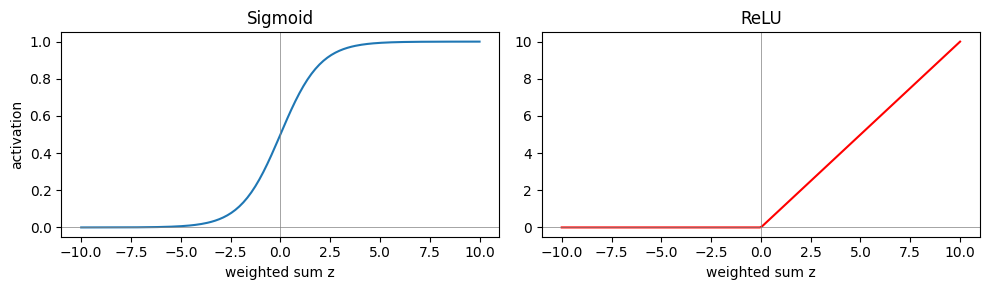

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

z = np.linspace(-10, 10, 200)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z, sigmoid(z))
axes[0].set_title("Sigmoid")
axes[0].set_ylabel("activation")
axes[1].plot(z, relu(z), "r")
axes[1].set_title("ReLU")
for ax in axes:
    ax.set_xlabel("weighted sum z")
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
plt.tight_layout()
plt.show()

+ **Sigmoid** squeezes any number into the range 0 to 1, so its output can be read as a probability. For large positive or negative $z$ the curve is almost flat, which slows learning down in deep networks.
+ **ReLU** returns $z$ when it is positive and 0 otherwise. It is cheap to compute and does not flatten out for positive inputs, which is why it is the default for hidden layers.

Now one neuron by hand, with NumPy. The input has three features, so the neuron has three weights and one bias. `np.dot(w, x)` multiplies each feature by its weight and adds the results up.

In [4]:
x = np.array([0.4, 1.2, 3.5])
w = np.array([1.0, 2.0, 1.0])
b = 1.3

z = np.dot(w, x) + b
y = sigmoid(z)

print("weighted sum z:", round(z, 2))
print("activation y:  ", round(y, 4))

weighted sum z: 7.6
activation y:   0.9995


The weighted sum is $1.0 \cdot 0.4 + 2.0 \cdot 1.2 + 1.0 \cdot 3.5 + 1.3 = 0.4 + 2.4 + 3.5 + 1.3 = 7.6$. Sigmoid turns 7.6 into 0.9995: far to the right on the curve above, where the output is almost 1. Change `w` or `b` and re-run the cell to watch the activation move.

### Multilayer neural networks

A single neuron can only draw a straight line (a hyperplane) between classes. To learn more complex patterns, we apply several sets of weights to the same input, which gives a **layer** of neurons, and stack layers so that each one takes the outputs of the previous one.

A multilayer network is a chain of matrix products (the weights) and activation functions. For a network with two layers:

$$ \mathbf{y} = \sigma\Big( W^1 \sigma\Big( W^0 \mathbf{x} + \mathbf{b}^0 \Big) + \mathbf{b}^1 \Big) $$

where $\sigma$ is applied to each element, and $W^i$ and $\mathbf{b}^i$ are the weights and biases of layer $i$ in matrix form.

Without the activation, the two layers would collapse into one: $W^1 (W^0 \mathbf{x})$ is just another matrix times $\mathbf{x}$, a linear model however many layers you stack. The activation is what makes stacking layers worth it.

It has been shown that a network with a single hidden layer and enough neurons can approximate any continuous function on a bounded region of $\mathbf{R}^n$ (the *universal approximation theorem*). That makes neural networks a sound choice for learning from data. The question is how to find good parameters $(W^i, \mathbf{b}^i)$ from a set of examples $\{(\mathbf{x}_1, \mathbf{y}_1), \dots, (\mathbf{x}_n, \mathbf{y}_n)\}$.

### How a network learns

There is no formula that gives the best parameters directly; for most models, including neural networks, there is no analytic solution. Instead we choose a **loss function** that measures how wrong the network is on the training data, and minimise it step by step. The standard method is **gradient descent**, and the gradient of the loss with respect to every weight is computed by **automatic differentiation** (backpropagation).

Write $f(\mathbf{x}_i)$ for the output of the network's last layer, $W^1 \sigma(W^0 \mathbf{x}_i + \mathbf{b}^0) + \mathbf{b}^1$ for the two-layer network above.

For **regression**, the usual loss is the mean squared error:

$$ L = \frac{1}{n} \sum_{i=1}^n \big(y_i - f(\mathbf{x}_i)\big)^2 $$

For **two-class classification**, with labels $y_i \in \{-1, 1\}$, the logistic loss:

$$ L = \frac{1}{n} \sum_{i=1}^n \log\big(1 + \exp(-y_i f(\mathbf{x}_i))\big) $$

Gradient descent and these losses are covered step by step in the gradient descent notebook.

### Playing with neural networks

The [TensorFlow Playground](https://playground.tensorflow.org) trains small networks in the browser and draws the decision boundary as they learn. Try these set-ups, and for each one watch the boundary and the test loss:

+ **Circle** data (one class inside the other), 1 hidden layer, **sigmoid** activation. How many neurons do you need?
+ The same, with **ReLU**. Does the boundary look different?
+ **Exclusive or** (XOR) data with **no hidden layer**. A single neuron draws a straight line, so it cannot separate the four corners.
+ XOR with **1 hidden layer**. How few neurons are enough?
+ **Spiral** data. Add layers and neurons, or extra input features, until it fits.
+ Switch the problem type to **regression**.

## 2. Deep learning in Keras

> Keras is a high-level neural networks library, written in Python, that runs on top of TensorFlow. It was developed with a focus on enabling fast experimentation.

The core data structure of Keras is a **model**, a way to organise layers. The simplest kind is the `Sequential` model: a linear stack of layers, where each layer feeds the next.

### The five steps of a Keras model

Every Keras model goes through the same five steps. The snippets below show them on placeholder data (`X_train`, `Y_train`, ...); the rest of this section runs them for real on handwritten digits.

**1. Build.** Create the model and stack layers with `.add()`. The first layer needs to know the shape of the input; the others work it out.

```python
model = keras.Sequential()
model.add(keras.Input(shape=(100,)))
model.add(layers.Dense(64, activation="relu"))
model.add(layers.Dense(10, activation="softmax"))
```

**2. Compile.** Choose the loss to minimise, the optimizer that minimises it, and the metrics to report.

```python
model.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
```

To configure the optimizer, pass an optimizer object instead of its name:

```python
model.compile(loss="categorical_crossentropy",
              optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True))
```

**3. Train.** Go over the training data in batches, for a number of epochs.

```python
model.fit(X_train, Y_train, epochs=5, batch_size=32)
```

**4. Evaluate.** Measure the loss and the metrics on data the model has not trained on.

```python
loss_and_metrics = model.evaluate(X_test, Y_test, batch_size=32)
```

**5. Predict.** Get the class probabilities for new data, and take the most likely class.

```python
proba = model.predict(X_test, batch_size=32)
classes = proba.argmax(axis=1)
```

### Check for a GPU

Deep learning libraries can train on a **GPU** (graphics card), which runs the many matrix products of a network in parallel. This cell lists the GPUs TensorFlow can see.

In [5]:
tf.config.list_physical_devices("GPU")

[]

An empty list `[]` means TensorFlow found no GPU and will use the CPU. That is fine here: this network is small and trains in about a second per epoch on a laptop. GPUs matter for large networks and image models.

### Load the data

**MNIST** is a classic dataset of handwritten digits: 60,000 training images and 10,000 test images, each 28 x 28 pixels in shades of grey, labelled with the digit it shows (0 to 9). It ships with Keras, and `load_data()` returns it already split into a training set and a test set.

In [6]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("training images:", x_train.shape, " labels:", y_train.shape)
print("test images:    ", x_test.shape, " labels:", y_test.shape)

training images: (60000, 28, 28)  labels: (60000,)
test images:     (10000, 28, 28)  labels: (10000,)


`x_train` holds 60,000 images of 28 x 28 pixels, and `y_train` the 60,000 matching labels. The test set has the same structure, with 10,000 images. Let's look at a few of them.

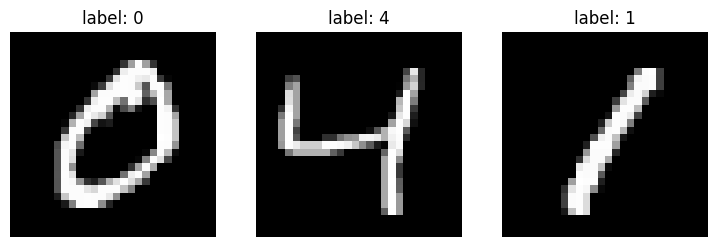

pixel values go from 0 to 255


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, i in zip(axes, [1, 2, 3]):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"label: {y_train[i]}")
    ax.axis("off")
plt.show()

print("pixel values go from", x_train.min(), "to", x_train.max())

Each image is just a grid of 28 x 28 numbers, from 0 (black) to 255 (white). The network never sees a picture, only these numbers.

### Prepare the data

A `Dense` layer expects each example as a flat vector of features, so the images need two changes:

+ **Flatten** each 28 x 28 image into a vector of $28 \times 28 = 784$ pixels. Each pixel becomes one input feature.
+ **Scale** the pixels from 0-255 to 0-1 by dividing by 255. Networks train much better when the inputs are small numbers on a similar scale, for the same reason we standardised features for logistic regression.

The results go into new variables, so `x_train` keeps the images for plotting, and the cell is safe to re-run.

In [8]:
x_train_flat = x_train.reshape(len(x_train), 784).astype("float32") / 255
x_test_flat = x_test.reshape(len(x_test), 784).astype("float32") / 255

print("training data:", x_train_flat.shape)
print("test data:    ", x_test_flat.shape)
print("pixel values now go from", x_train_flat.min(), "to", x_train_flat.max())

training data: (60000, 784)
test data:     (10000, 784)
pixel values now go from 0.0 to 1.0


Each row is now one image as 784 numbers between 0 and 1.

The labels need preparing too. They are digits from 0 to 9, and the network's last layer will have **10 neurons**, one per digit, with a **softmax** activation that turns their outputs into 10 probabilities adding up to 1. To compare that output with the true label, we write each label as a **one-hot** vector: ten zeros, with a 1 in the position of the digit.

In [9]:
num_classes = 10

y_train_cat = keras.utils.to_categorical(y_train, num_classes)
y_test_cat = keras.utils.to_categorical(y_test, num_classes)

print("label:  ", y_train[0])
print("one-hot:", y_train_cat[0])

label:   5
one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


The first training image is a 5, so its one-hot vector has its 1 in position 5 (counting from 0).

### Dropout

Our model will use **dropout**, so first, what it does.

Dropout is a way to **regularise** a neural network, that is, to keep it from overfitting. During training, a neuron can come to depend on one particular neuron in the previous layer, and the network ends up memorising the training data instead of learning patterns that generalise.

A `Dropout` layer prevents this by randomly switching off a fraction of the neurons in the previous layer at every training step:

+ **Rate:** the fraction of neurons dropped. `Dropout(0.2)` sets 20% of them to zero on each step.
+ **Different sub-networks:** a different random set is dropped each time, so in effect the network trains many smaller sub-networks, and no neuron can rely on any single other one.
+ **Training only:** dropout is active during `fit`. When the model evaluates or predicts, every neuron is used.

### Build the model

The model for the digits, layer by layer:

| Layer | Outputs | What it does |
|---|---|---|
| `Input(shape=(784,))` | 784 | One input per pixel |
| `Dense(16, activation="relu")` | 16 | First hidden layer; "dense" means every neuron is connected to all 784 inputs |
| `Dropout(0.2)` | 16 | Switches off 20% of those 16 outputs at each training step |
| `Dense(32, activation="relu")` | 32 | Second hidden layer |
| `Dropout(0.2)` | 32 | Switches off 20% of those 32 outputs at each training step |
| `Dense(10, activation="softmax")` | 10 | Output layer: one probability per digit |

The hidden layers use ReLU, the default for hidden layers. The output layer uses softmax because this is a classification into 10 classes, and its size has to match the number of classes.

In [10]:
model = keras.Sequential()
model.add(keras.Input(shape=(784,)))
model.add(layers.Dense(16, activation="relu"))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(32, activation="relu"))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(num_classes, activation="softmax"))

`model.summary()` lists the layers with their output shapes and the number of parameters each one learns.

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │        12,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,434 (52.48 KB)

 Trainable params: 13,434 (52.48 KB)

 Non-trainable params: 0 (0.00 B)

Where the parameter counts come from: a `Dense` layer has one weight per input for each of its neurons, plus one bias per neuron.

+ First hidden layer: $784 \times 16 + 16 = 12{,}560$
+ Second hidden layer: $16 \times 32 + 32 = 544$
+ Output layer: $32 \times 10 + 10 = 330$

That makes **13,434** parameters in total. Dropout layers have none: they only switch neurons off. Training means finding good values for all 13,434 numbers.

### Compile the model

`compile` sets three things:

+ **Loss:** `categorical_crossentropy`, the standard loss for multiclass classification with one-hot labels. It is small when the network gives a high probability to the correct digit.
+ **Optimizer:** the variant of gradient descent that updates the weights. Here **Adagrad**, which adapts the step size of each weight separately; [section 3](#3.-Keras-optimizers) explains it and the alternatives.
+ **Metrics:** `accuracy`, reported during training for us to read. The optimizer only looks at the loss.

In [12]:
optimizer = keras.optimizers.Adagrad(learning_rate=0.01, epsilon=0.1)

model.compile(loss="categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

### Train the model

`fit` runs gradient descent over the training data:

+ **`batch_size=64`:** the weights are updated after every 64 images, using the average gradient over those 64. With 60,000 training images that is $60{,}000 / 64 \approx 938$ updates per epoch: the `938/938` in the log.
+ **`epochs=20`:** one epoch is one pass over all the training images, so the network sees each image 20 times.
+ **`validation_data`:** after each epoch, Keras measures the loss and accuracy on these images, which are not used for training. Here we pass the test set to keep the example short; in a real project you would keep a separate validation set and use the test set only once, at the end.

`fit` carries on from the current weights, so running this cell again trains the same model further. To start from scratch, re-run the cells from **Build the model**.

In [13]:
history = model.fit(x_train_flat, y_train_cat,
                    batch_size=64,
                    epochs=20,
                    validation_data=(x_test_flat, y_test_cat),
                    verbose=2)

Epoch 1/20


938/938 - 1s - 1ms/step - accuracy: 0.5822 - loss: 1.2666 - val_accuracy: 0.8663 - val_loss: 0.5228


Epoch 2/20


938/938 - 1s - 760us/step - accuracy: 0.7642 - loss: 0.7441 - val_accuracy: 0.8906 - val_loss: 0.4020


Epoch 3/20


938/938 - 1s - 692us/step - accuracy: 0.7962 - loss: 0.6493 - val_accuracy: 0.8972 - val_loss: 0.3597


... (30 outputs left out)

Epoch 19/20


938/938 - 1s - 700us/step - accuracy: 0.8606 - loss: 0.4547 - val_accuracy: 0.9239 - val_loss: 0.2574


Epoch 20/20


938/938 - 1s - 690us/step - accuracy: 0.8611 - loss: 0.4542 - val_accuracy: 0.9248 - val_loss: 0.2548


Each line is one epoch: the loss and accuracy on the training batches, then `val_loss` and `val_accuracy` on the validation images. `fit` returns a `history` object with those numbers for every epoch, and plotting them is the quickest way to see how training went.

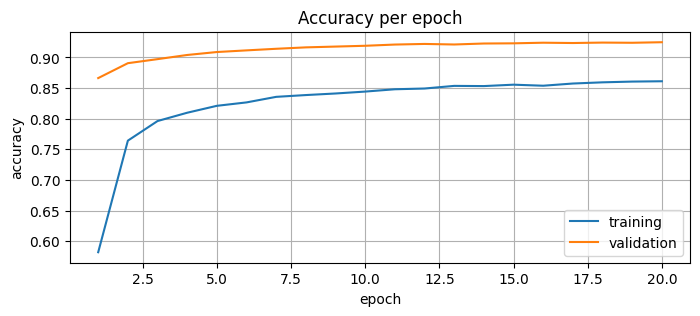

In [14]:
epochs = range(1, len(history.history["accuracy"]) + 1)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(epochs, history.history["accuracy"], label="training")
ax.plot(epochs, history.history["val_accuracy"], label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy per epoch")
ax.legend()
ax.grid(True)
plt.show()

@@CURVES_NOTE@@

### Evaluate the model

`evaluate` computes the loss and the metrics on the test set, with dropout switched off.

In [15]:
test_loss, test_accuracy = model.evaluate(x_test_flat, y_test_cat, verbose=0)

print("Test loss:    ", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss:     0.2548
Test accuracy: 0.9248


A test accuracy of @@TEST_ACC_PCT@@ means the network gets about @@TEST_WRONG@@ of the 10,000 test digits wrong. That is a reasonable start for 13,434 parameters, and there is plenty of room to improve: the original Keras example this code comes from uses two hidden layers of 512 neurons and the RMSprop optimizer, and reaches about 98%. Once the notebook has run, try `keras.optimizers.Adam(learning_rate=0.001)` in **Compile the model**, or wider layers, re-run from **Build the model**, and compare.

## 3. Keras optimizers

The digit model used Adagrad. There are several variants of gradient descent, which differ in how they compute each step. These are the most common ones in Keras, with their usual starting values:

```python
my_opt = keras.optimizers.SGD(learning_rate=0.01, momentum=0.0, nesterov=False)
my_opt = keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9)
my_opt = keras.optimizers.Adagrad(learning_rate=0.01)
my_opt = keras.optimizers.Adadelta(learning_rate=1.0, rho=0.95)
my_opt = keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, amsgrad=False)
my_opt = keras.optimizers.Adamax(learning_rate=0.002, beta_1=0.9, beta_2=0.999)
my_opt = keras.optimizers.Nadam(learning_rate=0.002, beta_1=0.9, beta_2=0.999)
```

In all of them, `learning_rate` is the step size $\alpha$. Most variants build on two ideas: **momentum**, and a **separate step size for each parameter**.

### Momentum

Plain SGD has trouble navigating ravines, that is, areas where the surface curves much more steeply in one direction than in another, which are common around local optima. There, SGD oscillates across the slopes of the ravine while making only hesitant progress along the bottom towards the optimum.

**Momentum** helps SGD accelerate in the relevant direction and dampens the oscillations. It adds a fraction $m$ of the previous update to the current one:

$$ v_t = m v_{t-1} + \alpha \nabla_w f $$

$$ w = w - v_t $$

The momentum $m$ is commonly set to $0.9$.

### Adagrad

SGD uses the same learning rate for every parameter. Tuning learning rates is expensive, so a lot of work has gone into methods that adapt the learning rate automatically, and even do so per parameter.

**Adagrad** does just this: it keeps, for each parameter, a running sum $c$ of its squared gradients, and divides the step by $\sqrt{c}$. Parameters that have received large or frequent updates get smaller steps, and rarely updated parameters get larger ones.

$$ c = c + (\nabla_w f)^2 $$
$$ w = w - \frac{\alpha}{\sqrt{c}} \nabla_w f $$

**Adam**, the most common default today, combines both ideas: momentum, and a step size per parameter.